# 03 · What makes an alert worth a call?

Notebook 02 produced an accurate demand forecast, yet projecting stock from the last report raised many false alarms. This notebook finds out why, and how many calls an officer needs to cover the real shortages. All results use the June–September 2026 test months of the simulated history.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from supplysignal.decisions import create_queue
from supplysignal.workload_eval import POLICIES, order_cases, score_calls

PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RUN = PROJECT / "artifacts/notebook-run"
OUT = PROJECT / "reports/analysis"
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
TEAL, RED, GOLD = "#237a80", "#c35c43", "#be9d49"

## 1. Load the test forecasts

These are notebook 02's held-out forecasts. An alert is raised when the last reported stock, run forward by the forecast for the months since that report, falls short.

In [2]:
preds = pd.read_csv(RUN / "test_predictions.csv")
report = json.loads((RUN / "training_report.json").read_text())
ledger = pd.read_csv(PROJECT / "data/processed/synthetic_lmis.csv")

forecast = preds["prediction_" + report["selected_model"]]
shortage = preds.actual_stockout.astype(bool)
preds["error"] = forecast - preds.actual_demand
preds["abs_error"] = preds.error.abs()
preds["baseline_abs_error"] = (preds.prediction_mean_last_3_reports - preds.actual_demand).abs()
preds["alert"] = preds.last_closing_stock.notna() & preds.report_age_months.le(2) & (preds.report_age_months * forecast > preds.last_closing_stock)
preds["true_alert"] = preds.alert & shortage
preds["false_alert"] = preds.alert & ~shortage
print(f"{len(preds)} test forecasts · {int(preds.true_alert.sum())} real shortages flagged · {int(preds.false_alert.sum())} false alarms")

336 test forecasts · 10 real shortages flagged · 220 false alarms


## 2. Forecast quality by medicine and report age

Error is broken down by medicine and by the age of the newest report, to check the forecast is sound across groups.

In [3]:
def summarise(group):
    return pd.Series({
        "rows": len(group),
        "wape": group.abs_error.sum() / group.actual_demand.sum(),
        "baseline_wape": group.baseline_abs_error.sum() / group.actual_demand.sum(),
        "bias": group.error.mean(),
        "real_flags": int(group.true_alert.sum()),
        "false_alarms": int(group.false_alert.sum()),
    })

by_product = preds.groupby("commodity_id").apply(summarise, include_groups=False)
by_age = preds.groupby("report_age_months", dropna=False).apply(summarise, include_groups=False)
display(by_product)
by_age

,rows,wape,baseline_wape,bias,real_flags,false_alarms
commodity_id,,,,,,
magnesium_sulfate,112.0,0.164176,0.194985,-0.243275,0.0,68.0
misoprostol,112.0,0.157125,0.186229,-1.013003,4.0,70.0
oxytocin,112.0,0.182304,0.191579,0.261598,6.0,82.0


,rows,wape,baseline_wape,bias,real_flags,false_alarms
report_age_months,,,,,,
2,297.0,0.167029,0.193352,-0.384587,10.0,220.0
3,38.0,0.160757,0.145455,0.131353,0.0,0.0
4,1.0,0.271644,0.416667,-2.173155,0.0,0.0


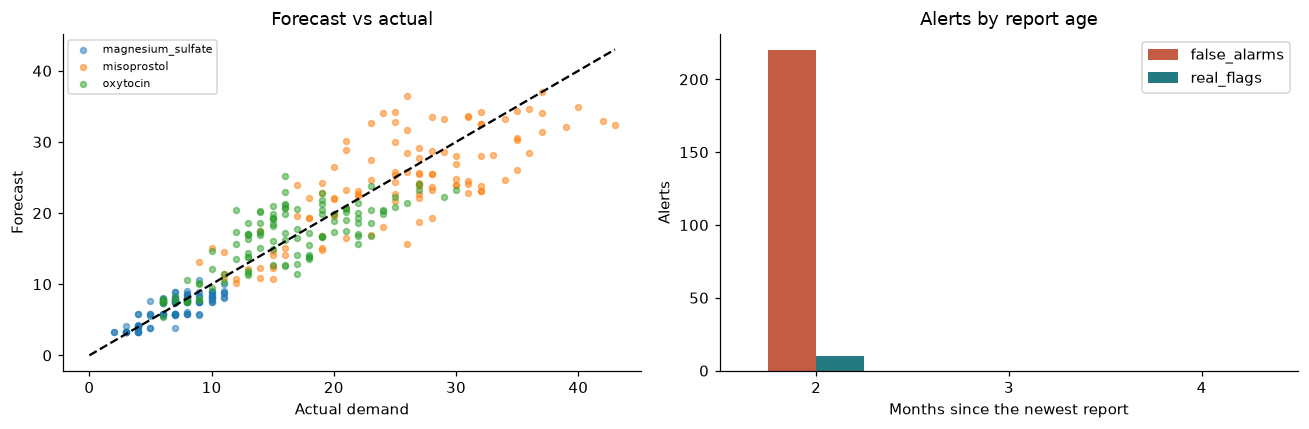

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for product, group in preds.groupby("commodity_id"):
    axes[0].scatter(group.actual_demand, forecast[group.index], alpha=0.5, label=product, s=15)
limit = max(preds.actual_demand.max(), forecast.max())
axes[0].plot([0, limit], [0, limit], "k--")
axes[0].legend(fontsize=7)
axes[0].set(xlabel="Actual demand", ylabel="Forecast", title="Forecast vs actual")
by_age[["false_alarms", "real_flags"]].plot.bar(ax=axes[1], color=[RED, TEAL], rot=0)
axes[1].set(xlabel="Months since the newest report", ylabel="Alerts", title="Alerts by report age")
fig.tight_layout()
plt.show()

## 3. Why the false alarms happen

Keep the **same forecast** and change only what the rule knows about stock, on the same rows:

1. the last monthly report available at the forecast date;
2. the simulator's true month-opening stock;
3. that opening stock plus all receipts over the target month.

This is a retrospective information diagnostic on the same 275 rows, including 10 shortages. Full-month receipts may arrive after the forecast date; a call at that date cannot reveal future deliveries. The comparison shows sensitivity to stock information, not an achievable live false-alarm rate or a causal estimate.

In [5]:
joined = preds.merge(
    ledger[["facility_id", "commodity_id", "period", "opening_stock", "receipts"]],
    left_on=["facility_id", "commodity_id", "target_period"],
    right_on=["facility_id", "commodity_id", "period"],
    validate="one_to_one",
)
rows = joined.dropna(subset=["opening_stock", "receipts", "last_closing_stock", "report_age_months"])
rows = rows[rows.report_age_months.le(2)]
real = rows.actual_stockout.astype(bool)
demand = rows["prediction_" + report["selected_model"]]

scenarios = {
    "Last monthly report": rows.report_age_months * demand > rows.last_closing_stock,
    "Month-opening stock (hindsight)": demand > rows.opening_stock,
    "Plus full-month receipts (hindsight)": demand > rows.opening_stock + rows.receipts,
}
information = pd.DataFrame([
    {
        "scenario": name,
        "rows": len(rows),
        "real_shortages": int(real.sum()),
        "caught": int((flag & real).sum()),
        "false_alarms": int((flag & ~real).sum()),
        "missed": int((~flag & real).sum()),
    }
    for name, flag in scenarios.items()
]).set_index("scenario")
information.to_csv(OUT / "information_diagnostic.csv")
information

,rows,real_shortages,caught,false_alarms,missed
scenario,,,,,
Last monthly report,275,10,10,201,0
Month-opening stock (hindsight),275,10,10,49,0
Plus full-month receipts (hindsight),275,10,10,1,0


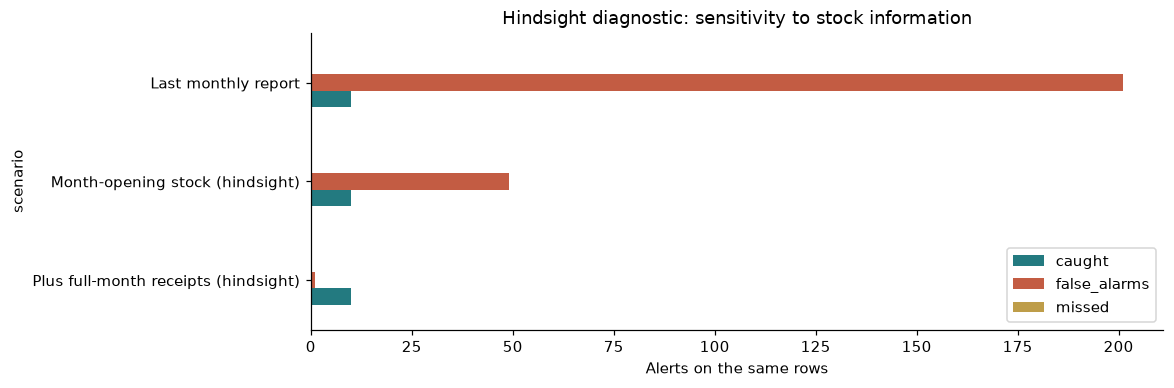

In [6]:
fig, ax = plt.subplots(figsize=(10, 3.5))
information[["caught", "false_alarms", "missed"]].iloc[::-1].plot.barh(ax=ax, color=[TEAL, RED, GOLD])
ax.set(xlabel="Alerts on the same rows", title="Hindsight diagnostic: sensitivity to stock information")
plt.show()

Steps 2 and 3 use simulator information that is not fully available at prediction time. A current count and subsequently confirmed receipts are useful operational inputs, but this experiment does not show that all this information can be obtained at the forecast date.

## 4. How many calls does an officer need?

Each call checks every flagged medicine at one clinic. For each test month we score call lists of 5, 10, 20 and 28 clinics, ordered in three ways, and count how many shortage products are covered.

In [7]:
budgets = [5, 10, 20, 28]
results = []
for month in pd.date_range("2026-06-01", "2026-09-01", freq="MS"):
    outcomes = {
        (row.facility_id, row.commodity_id): float(row.truth_unmet_units)
        for row in ledger[ledger.period.eq(month.date().isoformat())].itertuples()
    }
    cases = create_queue(month.date(), forecast_strategy="model", priority_policy="absolute_gap")
    for policy in POLICIES:
        for capacity in budgets:
            results.append({"month": month.date().isoformat(), "policy": policy, "capacity": capacity, **score_calls(order_cases(cases, policy), outcomes, capacity)})

monthly = pd.DataFrame(results)
measures = ["facility_calls", "product_checks", "shortage_calls", "calls_without_shortage", "shortage_product_checks",
            "missed_shortage_products", "event_products", "candidate_event_products", "unmet_units_found", "total_unmet_units"]
totals = monthly.groupby(["policy", "capacity"])[measures].sum().reset_index()
totals["shortage_coverage"] = totals.shortage_product_checks / totals.event_products
monthly.to_csv(OUT / "decision_capacity_monthly.csv", index=False)
totals.to_csv(OUT / "decision_capacity_summary.csv", index=False)
totals.pivot(index="capacity", columns="policy", values="shortage_coverage").style.format("{:.0%}")

policy,Oldest-report first,Reported-zero first,SupplySignal gap
capacity,,,
5,18%,18%,27%
10,73%,45%,45%
20,100%,100%,73%
28,100%,100%,100%


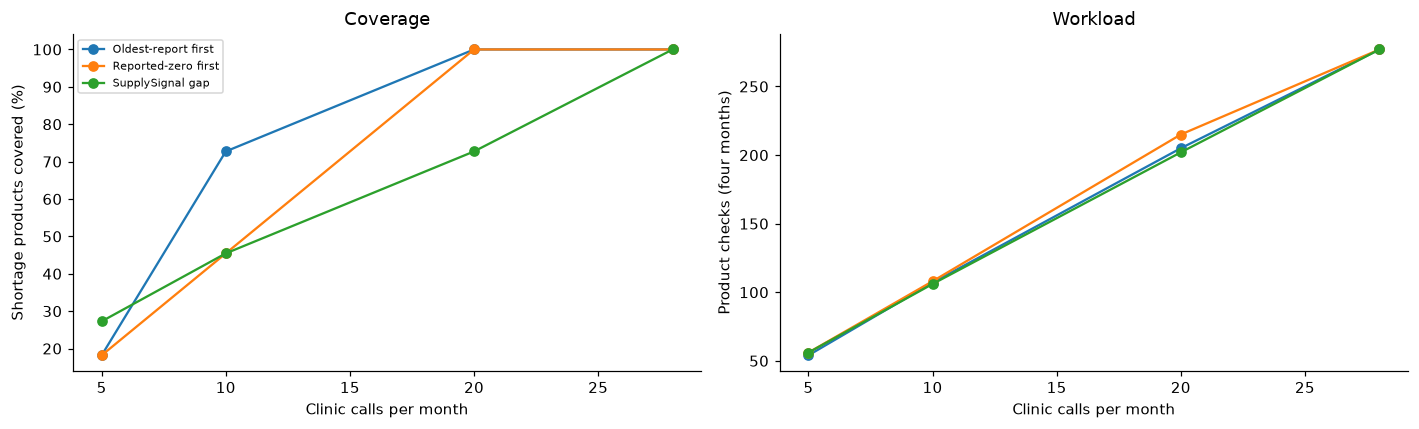

10 calls a month: 45%–73% of shortage products, depending on call order
Oldest-report-first reaches 100% at 20 calls; calling all 28 clinics covers 100%


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for policy, group in totals.groupby("policy"):
    axes[0].plot(group.capacity, group.shortage_coverage * 100, marker="o", label=policy)
    axes[1].plot(group.capacity, group.product_checks, marker="o", label=policy)
axes[0].set(xlabel="Clinic calls per month", ylabel="Shortage products covered (%)", title="Coverage")
axes[1].set(xlabel="Clinic calls per month", ylabel="Product checks (four months)", title="Workload")
axes[0].legend(fontsize=7)
fig.tight_layout()
plt.show()

coverage = totals.pivot(index="capacity", columns="policy", values="shortage_coverage")
print(f"10 calls a month: {coverage.loc[10].min():.0%}–{coverage.loc[10].max():.0%} of shortage products, depending on call order")
print(f"Oldest-report-first reaches {coverage.loc[20, 'Oldest-report first']:.0%} at 20 calls; calling all 28 clinics covers {coverage.loc[28].min():.0%}")

## What this means

- **Stock information materially changes these simulated alerts.** With the same forecast, hindsight month-opening stock reduces false alarms from 201 to 49; full-month receipts reduce them to 1, retaining all 10 shortages in the eligible subset. This is not a live performance claim. So every alert in SupplySignal starts as a quick verification call, and receipts are recorded as evidence.
- **Report freshness is the strongest call-order signal.** Ordering calls by oldest report covers the most shortages per call (73% with 10 calls, all of them with 20), which supports investigating freshness as a priority signal in this simulator. Testing a freshness-first call order is a pilot priority.
- **Next data priority for a pilot:** timestamped stock counts and delivery receipts, which are exactly what the app collects.